In [1]:
from google.colab import files

uploaded = files.upload()

Saving 1661-0.txt to 1661-0.txt


In [2]:
import re
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.metrics import top_k_accuracy_score

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [3]:
# Load the uploaded dataset
file_name = "1661-0.txt"

with open(file_name, "r", encoding="utf-8-sig") as file:
    text = file.read()

# Remove Project Gutenberg header and footer
start_marker = "*** START OF THIS PROJECT GUTENBERG EBOOK"
end_marker = "*** END OF THIS PROJECT GUTENBERG EBOOK"

if start_marker in text:
    text = text.split(start_marker, 1)[1]

if end_marker in text:
    text = text.split(end_marker, 1)[0]

# Convert text to lowercase
text = text.lower()

# Keep letters, apostrophes, and sentence punctuation
text = re.sub(r"[^a-z\s.!?']", " ", text)
text = re.sub(r"\s+", " ", text)

# Split text into sentences
sentences = re.split(r'(?<=[.!?])\s+', text)

# Remove short or empty sentences
sentences = [
    s.strip() for s in sentences
    if len(s.split()) >= 3
]

# Use up to 10,000 sentences
sentences = sentences[:10000]

print("Total sentences:", len(sentences))
print("\nSample sentences:")
for sentence in sentences[:5]:
    print(sentence)

Total sentences: 6551

Sample sentences:
the adventures of sherlock holmes produced by an anonymous project gutenberg volunteer and jose menendez cover the adventures of sherlock holmes by arthur conan doyle contents i.
a scandal in bohemia ii.
the red headed league iii.
a case of identity iv.
the boscombe valley mystery v.


In [4]:
# Create the tokenizer
MAX_WORDS = 8000

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(sentences)

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

print("Vocabulary size:", vocab_size)

# Display some word-to-number mappings
print("\nSample vocabulary:")
for word, index in list(tokenizer.word_index.items())[:15]:
    print(word, ":", index)

Vocabulary size: 7803

Sample vocabulary:
<OOV> : 1
the : 2
and : 3
i : 4
to : 5
of : 6
a : 7
in : 8
that : 9
it : 10
you : 11
he : 12
was : 13
his : 14
is : 15


In [5]:
input_sequences = []

# Convert each sentence into word IDs
for sentence in sentences:
    token_list = tokenizer.texts_to_sequences([sentence])[0]

    # Generate sequences with the next word as target
    for i in range(2, len(token_list)):
        input_sequences.append(token_list[:i + 1])

print("Total sequences:", len(input_sequences))

# Use a maximum of 10 previous words as context
MAX_LEN = 11

# Pad all sequences to the same length
input_sequences = pad_sequences(
    input_sequences,
    maxlen=MAX_LEN,
    padding="pre",
    truncating="pre"
)

# Separate inputs and target words
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nExample input word IDs:", X[0])
print("Example target word ID:", y[0])

Total sequences: 91668
Input shape: (91668, 10)
Target shape: (91668,)

Example input word IDs: [   0    0    0    0    0    0    0    0    2 1227]
Example target word ID: 6


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 73334
Testing samples: 18334


In [7]:
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(96),

    Dropout(0.2),

    Dense(vocab_size, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 44s 72ms/step - accuracy: 0.0553 - loss: 6.7274 - val_accuracy: 0.0571 - val_loss: 6.4270
Epoch 2/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 38s 74ms/step - accuracy: 0.0720 - loss: 6.2056 - val_accuracy: 0.0781 - val_loss: 6.2876
Epoch 3/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 38s 73ms/step - accuracy: 0.0841 - loss: 5.9993 - val_accuracy: 0.0863 - val_loss: 6.1956
Epoch 4/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 37s 71ms/step - accuracy: 0.0972 - loss: 5.8319 - val_accuracy: 0.0904 - val_loss: 6.1159
Epoch 5/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 45s 78ms/step - accuracy: 0.1125 - loss: 5.6730 - val_accuracy: 0.1050 - val_loss: 6.0425


In [9]:
# Evaluate model loss and accuracy
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=128,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Top-1 Accuracy: {test_accuracy * 100:.2f}%")

# Calculate Top-5 accuracy on a manageable test sample
sample_size = min(3000, len(X_test))

X_eval = X_test[:sample_size]
y_eval = y_test[:sample_size]

probabilities = model.predict(
    X_eval,
    batch_size=128,
    verbose=1
)

# Highest-probability word
top1_predictions = np.argmax(probabilities, axis=1)
top1_accuracy = np.mean(top1_predictions == y_eval)

# Five highest-probability words
top5_predictions = np.argpartition(
    probabilities,
    -5,
    axis=1
)[:, -5:]

top5_accuracy = np.mean(
    np.any(top5_predictions == y_eval[:, None], axis=1)
)

print(f"Top-1 Accuracy: {top1_accuracy * 100:.2f}%")
print(f"Top-5 Accuracy: {top5_accuracy * 100:.2f}%")

144/144 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.1123 - loss: 6.0433
Test Loss: 6.0433
Test Top-1 Accuracy: 11.23%
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step
Top-1 Accuracy: 10.87%
Top-5 Accuracy: 27.03%


In [10]:
def predict_next_word(phrase):
    # Convert phrase into numerical IDs
    sequence = tokenizer.texts_to_sequences([phrase.lower()])[0]

    # Keep the most recent words if the phrase is long
    sequence = sequence[-(MAX_LEN - 1):]

    # Add padding
    padded = pad_sequences(
        [sequence],
        maxlen=MAX_LEN - 1,
        padding="pre"
    )

    # Predict probabilities
    predictions = model.predict(padded, verbose=0)[0]

    # Get the five most probable word IDs
    top_indices = np.argsort(predictions)[-5:][::-1]

    print("\nInput phrase:", phrase)
    print("Predicted next words:")

    for index in top_indices:
        word = tokenizer.index_word.get(index, "<unknown>")
        print(f"{word}: {predictions[index] * 100:.2f}%")


# Test with five different phrases
test_phrases = [
    "sherlock holmes",
    "the old man",
    "he looked at",
    "it was a",
    "i think that"
]

for phrase in test_phrases:
    predict_next_word(phrase)


Input phrase: sherlock holmes
Predicted next words:
was: 3.50%
is: 2.62%
had: 2.32%
i: 1.75%
that: 1.24%

Input phrase: the old man
Predicted next words:
of: 10.41%
and: 7.62%
was: 4.02%
is: 2.85%
in: 2.54%

Input phrase: he looked at
Predicted next words:
the: 32.03%
a: 7.62%
his: 5.79%
my: 3.85%
me: 2.64%

Input phrase: it was a
Predicted next words:
man: 1.19%
little: 1.17%
door: 0.84%
room: 0.80%
very: 0.67%

Input phrase: i think that
Predicted next words:
i: 12.03%
he: 10.10%
you: 9.58%
the: 7.11%
it: 6.49%


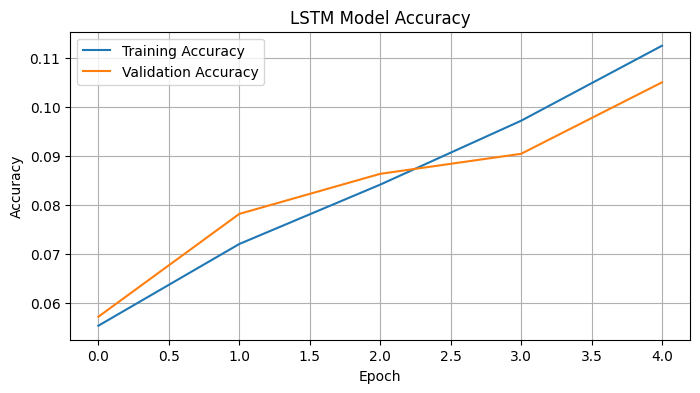

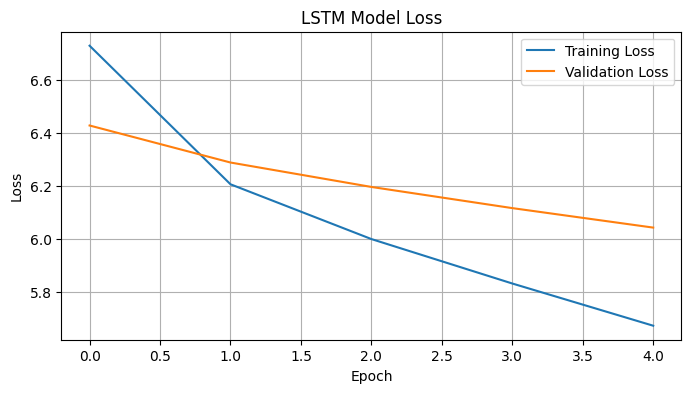

In [11]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 4))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation loss
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
# Next-Word Prediction - Testing

def predict_next_word(phrase):
    sequence = tokenizer.texts_to_sequences([phrase.lower()])[0]

    # Keep only the latest words
    sequence = sequence[-(MAX_LEN - 1):]

    # Padding
    padded = pad_sequences(
        [sequence],
        maxlen=MAX_LEN - 1,
        padding="pre"
    )

    # Predict next word
    predictions = model.predict(padded, verbose=0)[0]

    # Get top 5 predictions
    top_indices = np.argsort(predictions)[-5:][::-1]

    print("\nInput:", phrase)
    print("Predicted next words:")

    for index in top_indices:
        word = tokenizer.index_word.get(index, "<unknown>")
        print(f"{word} : {predictions[index] * 100:.2f}%")

# Test with 5 sample inputs
test_inputs = [
    "sherlock holmes",
    "the old man",
    "he looked at",
    "it was a",
    "i think that"
]

for phrase in test_inputs:
    predict_next_word(phrase)


Input: sherlock holmes
Predicted next words:
was : 3.50%
is : 2.62%
had : 2.32%
i : 1.75%
that : 1.24%

Input: the old man
Predicted next words:
of : 10.41%
and : 7.62%
was : 4.02%
is : 2.85%
in : 2.54%

Input: he looked at
Predicted next words:
the : 32.03%
a : 7.62%
his : 5.79%
my : 3.85%
me : 2.64%

Input: it was a
Predicted next words:
man : 1.19%
little : 1.17%
door : 0.84%
room : 0.80%
very : 0.67%

Input: i think that
Predicted next words:
i : 12.03%
he : 10.10%
you : 9.58%
the : 7.11%
it : 6.49%
